k- 최근접 이웃 회귀(knr)에 대해 알아보자.

회귀 알고리즘은 knn과는 다르게, 값의 클래스를 찾는 것이 아닌 **값을 예측하는 것**이다.
값을 예측하는 원리는 간단하다.

가까운 `n_neighbors`에 대하여 해당 값들의 평균을 구해 값을 예측해낸다.

실제 예시를 보며 정확히 설명하겠다.

사용되는 자료에서, 농어의 길이인 `perch_length`가 특성이고, 농어의 무게인 `perch_weight`가 타깃이다.

In [2]:
import numpy as np
perch_length = np.array([8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0, 21.0,
       21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5, 22.5, 22.7,
       23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5, 27.3, 27.5, 27.5,
       27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0, 36.5, 36.0, 37.0, 37.0,
       39.0, 39.0, 39.0, 40.0, 40.0, 40.0, 40.0, 42.0, 43.0, 43.0, 43.5,
       44.0])
perch_weight = np.array([5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0, 110.0,
       115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0, 130.0,
       150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0, 197.0,
       218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0, 514.0,
       556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0, 820.0,
       850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0, 1000.0,
       1000.0])

이제 이 데이터의 형태를 보기 위해 산점도를 그려보자.

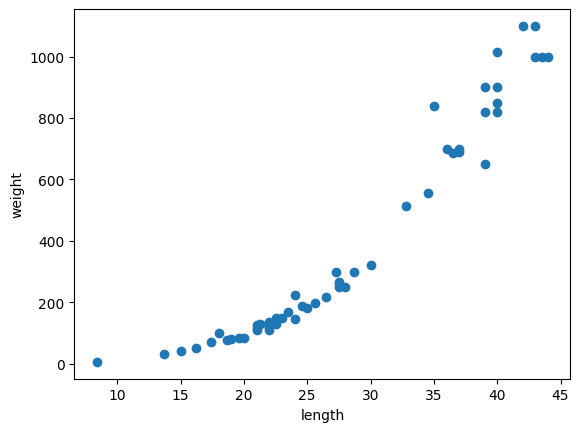

In [3]:
import matplotlib.pyplot as plt
plt.scatter(perch_length, perch_weight)
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

농어의 길이가 커짐에 따라 무게도 늘어난다.
당연한 현상이다.
이번엔 데이터를 훈련 세트와 테스트 세트로 나누어보자.

In [ ]:
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(perch_length, perch_weight, random_state=42)

이번 예제는 특성이 1차원 배열이므로, `numpy`에서 제공하는 메소드를 이용해 구조를 변경해야 한다.

배열의 차원 구조를 변경하는 메소드는 `reshape()` 이다.
```python
reshape(행, 열)
```
> `reshape()`는 비파괴적으로 배열을 변경한다.
> 리턴값을 배열에 다시 저장하여야 한다.

> 변경하려는 구조의 배열의 크기를 자동으로 지정되게 하려면 첫 번째 매개변수로 `-1`을 입력한다.


다음 1차원의 예시 배열로 테스트해보자.

In [6]:
test_array = np.array([1, 2, 3, 4])
test_array.shape

(4,)

4개의 인덱스가 있는 1차원 배열이다.
이제 `(2, 2)` 형태로 변경해보자.
> numpy 배열의 `shape` 속성의 출력 튜플 2번째 인덱스의 값은 1차원 일 때 값이 없다.


In [10]:
test_array = test_array.reshape(2, 2)
print(test_array)
print(test_array.shape)

[[1 2]
 [3 4]]
(2, 2)


배열이 2개의 인덱스씩 나누어져 출력되었다.
배열의 구조도 `(2, 2)`로 기대한 대로 출력된다.

>`reshape()`의 지정된 배열의 원본 인덱스의 개수가 변경하려는 배열 구조의 인덱스 개수와 같지 않으면 `ValueError` 예외가 발생한다.

이제 실제 데이터 세트의 구조를 변경하자.

In [16]:
train_input = train_input.reshape(-1,1)
test_input = test_input.reshape(-1, 1)
print(train_input.shape, test_input.shape)

(42, 1) (14, 1)


`-1`을 사용해 배열의 전체 요소의 개수를 입력하지 않고, 자동적으로 2차원 배열로 사용했다.
> 이전에 설명하였듯이, knn과 knr에서 모델을 훈련하고 사용하기 위해서는 2차원 배열로 입력받는다.

데이터 세트가 준비되었으니 이제 데이터를 훈련시키자.

# 훈련
`sklearn`에서 k- 최근접 이웃 회귀를 구현한 클래스는 `KNeighborsRegressor` 이다.
사용법은 `KNeighborsClassifier`와 동일하다.

In [17]:
from sklearn.neighbors import KNeighborsRegressor

knr = KNeighborsRegressor()
knr.fit(train_input, train_target)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


`knr` 모델을 훈련할 때, 매개변수에 입력값과 훈련 타깃값을 모두 입력해 회귀 모델을 생성했다.

이제 `score()` 메소드를 이용해 평가하자.

In [ ]:
knr.score(test_input, test_target)

0.992809406101064

점수는 `1.0`에 가깝게 높게 나왔다.
> 당연하게도, 점수가 `1.0`에 가까울수록 높은 정확성을 가진 모델이다.

결과로 출력된 `0.992809406101064`라는 점수는 테스트 입력값에서 타깃값을 맞춘 값의 비율이다.
백분율로 표현하면 100을 곱한 `99.2809406101064%`의 정확도이다.

회귀 알고리즘에서는 `100%`의 정확도가 나오는 것이 불가능하다.
예측하는 값이나 타깃 모두 임의의 수치이고, 실행하는 환경에 따라서도 결과값의 차이가 있기 때문이다.

회귀의 경우 모델을 평가할 때에는 결정계수 $R^2$로 평가한다.
간단히 $R^2$로 부른다.
다음과 같은 수식으로 사용된다.
$$
R^2 = 1 - \frac{\text{잔차 제곱합(Residual Sum of Squares, RSS)}}{\text{총 제곱합(Total Sum of Squares, TSS)}}
$$

* **RSS(Residual Sum of Squares)**: 모델이 예측한 값과 실제 값의 차이를 제곱하여 합한 것
* **TSS(Total Sum of Squares)**: 실제 값과 평균 값의 차이를 제곱하여 합한 것

즉,
$$
R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}
$$
로 표현이 가능하다.

여기서:
- $y_i$: 실제 타깃 값
- $\hat{y}_i$: 모델이 예측한 값
- $\bar{y}$: 타깃의 평균값

**계산 과정:**
1. 각 샘플의 타깃과 예측한 값의 차를 제곱하여 더한다 (분자: RSS)
2. 타깃과 타깃 평균의 차이를 제곱하여 더한 값으로 나눈다 (분모: TSS)
3. 이 비율을 1에서 뺀다

**$R^2$ 값의 해석:**
- 타깃의 평균 정도를 예측하는 수준이라면, 분자(RSS)와 분모(TSS)가 비슷해져 결정계수는 `0.0`에 가까워진다. 이는 모델이 단순히 평균값을 예측하는 것과 다름없음을 의미한다.
- 예측값이 타깃에 가까워지면 분자(RSS)가 0에 가까워져 `1.0`에 가까운 값이 된다. 이는 모델이 실제 값을 매우 정확하게 예측함을 의미한다.
- **$R^2 = 1.0$**: 완벽한 예측 (모든 예측값이 실제 값과 일치)
- **$R^2 = 0.0$**: 평균값을 예측하는 것과 같은 수준
- **$R^2 < 0.0$**: 평균값을 예측하는 것보다 나쁜 모델 (과적합 또는 부적절한 모델)

일반적으로 $R^2$가 높을수록 모델의 설명력이 좋다고 평가하지만, 특성이 많아질수록 $R^2$가 인위적으로 높아질 수 있으므로 주의가 필요하다.

실제 데이터를 `predict()`를 이용해 거리를 측정하여 증명이 맞는지 확인해보자.

`sklearn`은 `sklearn.metrics`에 여러 측정 메소드를 제공한다.
이 중 `mean_absolute_error` 메소드는 타깃과 예측의 절댓값 오차를 평균하여 계산한다.
> mean absolute error는 MAE로, 평균 절대 오차이다.
> 동일한 현상을 나타내는 관칙치간의 오류를 측정한 것이다.

평균 절대 오차값을 계산하여 보자.

In [20]:
from sklearn.metrics import mean_absolute_error

# 테스트 세트에 대한 예측을 만든다.
test_prediction = knr.predict(test_input)

# 테스트 세트에 대해 평균절대오차를 구한다.
mae = mean_absolute_error(test_target, test_prediction) # 첫 번째 매개변수에는 true 값인 target, 두 번째 매개변수에는 예측값
print(mae)

19.157142857142862


결과에서 예측값이 평균적으로 19 정도 다른 것을 볼 수 있다.

# 과대적합과 과소적합
지금까지는 모두 훈련 세트로 모델을 훈련하고, 테스트 세트로 모델을 평가했다.
이번에는 모델을 테스트 할 때, 훈련할 때 사용한 훈련 세트를 그대로 사용해보자.

이전에 훈련한 모델 객체인 `knr`에 그대로 `score()`에 훈련 세트를 전달하여 $R^2$값을 확인해보자.

In [24]:
knr.score(train_input, train_target)

0.9698823289099254

앞에서 테스트 세트를 사용한 점수와 비교해보자.
`99.2809406101064`와는 다르게, 약 96%의 정확도가 출력되었다.
> 약 3%의 차이가 나타난다.

일반적으로 모델을 훈련 세트로 훈련하면 훈련 세트에 맞는 모델이 만들어진다.
보통 모델을 테스트 할 때 모델을 훈련한 훈련 세트로 모델을 평가하면, 거의 완벽하게 평가되는 경우가 많다.
> Knn 알고리즘만 해도 그렇다.

만약, 훈련 세트에서 테스트했을 때 높은 점수가 나왔는데 테스트 세트(실제 모델 사용)에서 낮은 점수가 나왔다면,\
해당 모델은 **과대적합(overfitting)** 된 모델이다.\
훈련 세트에만 잘 맞추어진 모델이라 실 사용이나 새로운 샘플에 대한 예측에서는 정확히 동작하지 않을 것이다.


반대로, 훈련 세트보다 테스트 세트의 점수가 높거나 두 점수가 모두 낮은 경우에는\
훈련 세트에 **과소적합(underfitting)** 되었다고 한다.\
즉, 모델이 너무 단순해서 훈련 세트에 적절히 훈련되지 않은 경우이다.
> 이 경우에도 모델이 실사용에서 제대로 동작하지 않는다.

모델의 자유도와 응용 데이터의 학습 자체가 정확히 되지 않아서 일반적으로 과소적합이 일어난다.

> 훈련 세트와 테스트 점수를 비교하였을 때 훈련 세트가 너무 높으면 과대적합, 그 반대거나 둘 다 낮다면 과소적합니다.


현재 모델의 경우 훈련 세트의 점수가 테스트 세트의 점수보다 높으므로 **과소적합**이다.

이 문제를 해결하려면, 측정하는 모델을 조금 더 복잡하게 하면 된다.
k-최근접 이웃 계열의 모델의 복잡도를 높이려면 `n_neighbors` 값을 낮추면 된다.

`n_neighbors` 값이 높으면 데이터 전반에 분포된 데이터의 일반적인 패턴을 따를 것이다.
> 앞서 knn 모델에서 특히 명확히 드러난다.
값이 낮으면 모델의 국지적인 패턴에 민감해져 모델이 더 복잡해질 수 있다.

`sklearn`의 knn 계열 알고리즘의 `n_neighbors`의 기본값은 5이다.
현재 모델에서는 모델의 복잡성을 높이기 위해 이웃 참조값을 3으로 낮추어 모델을 확인해보겠다.

In [ ]:
knr.n_neighbors = 3 # type: ignore

# 모델을 다시 훈련한다.
knr.fit(train_input, train_target)

# 훈련 세트의 결정계수를 이용해 테스트한다.
print(knr.score(train_input, train_target))

0.9804899950518966


테스트 세트의 결정계수 값을 확인해보면

In [28]:
print(knr.score(test_input, test_target))

0.9746459963987609


결정계수의 편차 차이값이 1% 내외로 유지되고 있다.

예상대로 테스트 세트의 점수와 훈련 세트와의 점수 차가 줄어들었으므로 과소적합 문제도 해결되었다.
사용될 데이터에서도 일반화에 성공할 것이라 볼 수 있다.

회귀 모델을 성공적으로 훈련했다.

## 과대적합/과소적합 검증
과소적합을 해결하기 위해 `n_neighbors` 값을 낮추어 모델을 복잡하게 하는 방법을 사용했다.
아래 코드에서는 `n_neighbors` 값을 유동적으로 바꾸어 모델이 단순해짐을 시각화를 통해 확인한다.

d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50883 (\N{HANGUL SYLLABLE US}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pyl

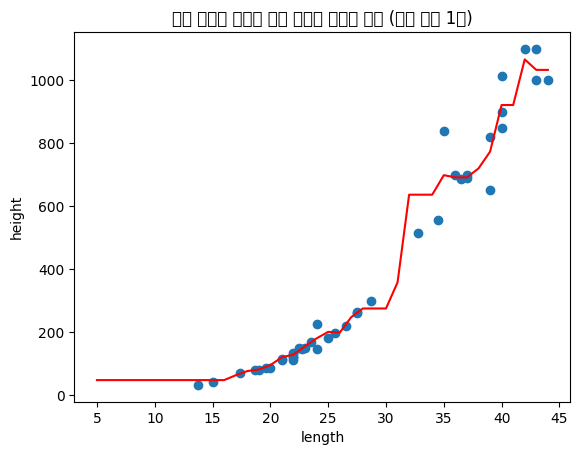

d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50883 (\N{HANGUL SYLLABLE US}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pyl

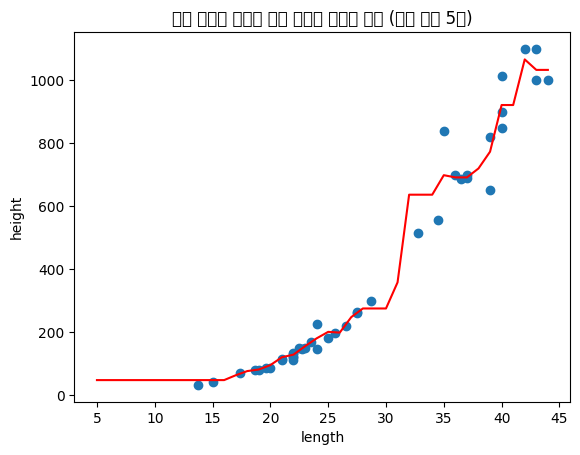

d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 52280 (\N{HANGUL SYLLABLE CAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50883 (\N{HANGUL SYLLABLE US}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 44050 (\N{HANGUL SYLLABLE GABS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\mldl\.venv\Lib\site-packages\IPython\core\pyl

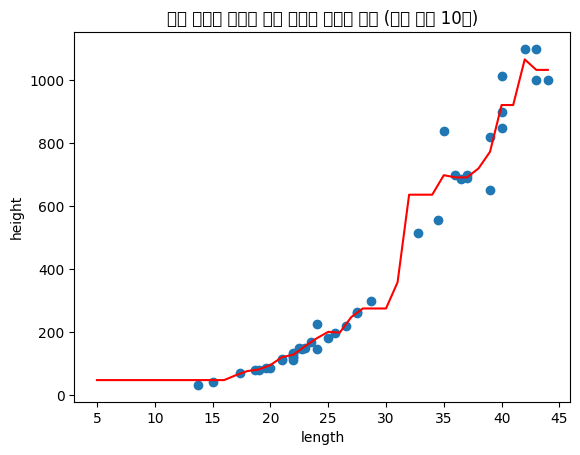

In [55]:
# k 최근접 이웃 회귀 객체 생성
knrtest = KNeighborsRegressor()
# 5에서 45까지 x 좌표를 생성한다.
x = np.arange(5, 45).reshape(-1, 1)

# n이 1, 5, 10 일 때 예측 결과를 matplotlib를 이용해 그린다.
for n in [1, 5, 10]:
    # 모델을 각각의 neighbors 값에서 훈련한다.
    knrtest.n_neighbors = n # type: ignore
    knr.fit(train_input, train_target)
    
    # 지정한 5와 45 사이의 범위 x의 예측을 구한다.
    prediction = knr.predict(x)

    # 훈련 세트와 예측 결과를 시각화한다.
    plt.scatter(train_input, train_target) # 학습값
    plt.plot(x, prediction, 'r')
    
    plt.title(f"참조 이웃값 변경에 따른 모델의 단순성 분석 (참조 이웃 {n}개)")
    plt.xlabel("length")
    plt.ylabel("height")
    plt.show()